# Credit Card Default Prediction

## 1. Introduction

This project investigates whether machine learning can predict the likelihood that a credit card customer will default on their payment obligations. The analysis uses demographic information, credit limits, repayment status, billing amounts and payment amounts from the preceding six months.

The project compares three classification approaches:

- **Logistic Regression**, used as a baseline model.
- **Decision Tree**, used to identify interpretable, rule-based patterns.
- **Random Forest**, an ensemble of decision trees used to investigate whether combining multiple trees improves predictive performance.

The target variable is `default`, where `1` represents a customer who defaulted and `0` represents a customer who did not.

The evaluation considers accuracy, precision, recall, F1-score and ROC-AUC. Particular attention is paid to the default class because the dataset is imbalanced and accuracy alone can conceal poor identification of defaulters.

## 2. Imports and Configuration

The following libraries support data preparation, visualisation, model development and evaluation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## 3. Dataset Overview

The original dataset is stored in `../data/credit_card_default_data.csv`. The first row contains the source column labels in the form `X1`, `X2`, etc., so it is skipped when loading the data. The target column is subsequently renamed to `default`, and `PAY_0` is renamed to `PAY_1` for consistency.

The notebook expects the `data` directory to sit alongside this notebook.

In [2]:
DATA_DIR = Path("../data")
RAW_DATA_PATH = DATA_DIR / "credit_card_default_data.csv"

df = pd.read_csv(RAW_DATA_PATH, skiprows=1)
df = df.rename(columns={
    "default payment next month": "default",
    "PAY_0": "PAY_1"
})

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn types:")
display(df.dtypes.to_frame("data type"))

Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0



Column types:


,data type
ID,int64
LIMIT_BAL,int64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_1,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64


### 3.1 Target distribution

Before modelling, the target distribution is examined to understand the class balance.

,Customers
default,
No default (0),23364
Default (1),6636


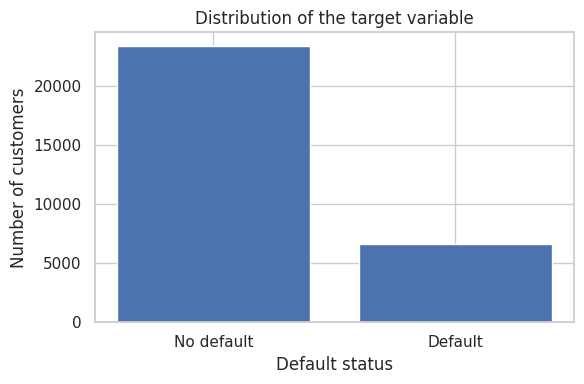

Default proportion: 22.12 %


In [3]:
target_counts = df["default"].value_counts().sort_index()
display(target_counts.rename(index={0: "No default (0)", 1: "Default (1)"}).to_frame("Customers"))

plt.figure(figsize=(6, 4))
plt.bar(["No default", "Default"], [target_counts.get(0, 0), target_counts.get(1, 0)])
plt.title("Distribution of the target variable")
plt.xlabel("Default status")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Default proportion:", round(df["default"].mean() * 100, 2), "%")

## 4. Data Preparation and Feature Engineering

The original categorical variables are converted into binary indicator variables. Undefined and ambiguous education and marital-status categories are not assigned interpretations; their corresponding dummy columns are excluded.

The six repayment-status columns (`PAY_1` to `PAY_6`) are used to derive behavioural measures:

- `no_spend_months_proportion`: proportion of months with repayment status `-2`.
- `payoff_months_proportion`: proportion of months with repayment status `-1`.
- `rollover_months_proportion`: proportion of months with repayment status `0`.
- `late_payment_rating`: average severity of late payments, normalised by the maximum status value of 8.

Financial measures are also engineered from the six monthly bill and payment observations, including average credit utilisation, bill trend slope, average bill amount, average payment amount and average repayment proportion.

The functions below reproduce the preprocessing approach used in the project scripts.

In [4]:
def encode_categorical(data, source_column, prefix, encoding):
    dummies = pd.get_dummies(data[source_column], prefix=prefix, dtype=int)
    data = data.drop(columns=[source_column]).join(dummies)
    rename = {f"{prefix}_{key}": f"{prefix}_{value}"
              for key, value in encoding.items() if value is not None}
    data = data.rename(columns=rename)
    drop = [f"{prefix}_{key}" for key, value in encoding.items() if value is None]
    return data.drop(columns=drop, errors="ignore")

def add_derived_behaviour_columns(data):
    pay_cols = [f"PAY_{i}" for i in range(1, 7)]
    total_months = len(pay_cols)
    data["no_spend_months_proportion"] = data[pay_cols].eq(-2).sum(axis=1) / total_months
    data["payoff_months_proportion"] = data[pay_cols].eq(-1).sum(axis=1) / total_months
    data["rollover_months_proportion"] = data[pay_cols].eq(0).sum(axis=1) / total_months
    late_sum = data[pay_cols].where(data[pay_cols] > 0, 0).sum(axis=1)
    late_months = data[pay_cols].gt(0).sum(axis=1)
    data["late_payment_rating"] = (late_sum / (late_months * 8)).fillna(0)
    return data

def add_financial_features(data):
    bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
    pay_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
    data["average_credit_utilisation"] = data[bill_cols].mean(axis=1) / data["LIMIT_BAL"].replace(0, np.nan)

    months = np.array([0, -1, -2, -3, -4, -5])
    data["bill_trend_slope"] = data[bill_cols].apply(
        lambda row: np.polyfit(months, row.to_numpy(dtype=float), 1)[0], axis=1
    )
    data["average_bill_amount"] = data[bill_cols].mean(axis=1)
    data["average_payment_amount"] = data[pay_cols].mean(axis=1)

    repayment_proportions = []
    for i in range(1, 6):
        previous_bill = data[f"BILL_AMT{i + 1}"]
        repayment_proportions.append(data[f"PAY_AMT{i}"] / previous_bill.where(previous_bill > 0))
    data["repayment_proportion_average_new"] = pd.concat(repayment_proportions, axis=1).mean(axis=1)
    return data

# Encode categorical variables.
df = encode_categorical(df, "SEX", "gender", {1: "male", 2: None})
df = encode_categorical(df, "EDUCATION", "educ", {
    0: None, 1: "post_grad", 2: "grad", 3: "high", 4: None, 5: None, 6: None
})
df = encode_categorical(df, "MARRIAGE", "rel", {
    0: None, 1: "married", 2: "single", 3: None
})

# Engineer behavioural and financial features.
df = add_derived_behaviour_columns(df)
df = add_financial_features(df)

# Remove rows for which the engineered averages/proportion cannot be calculated.
df = df.dropna(subset=[
    "average_bill_amount", "average_payment_amount", "repayment_proportion_average_new"
]).copy()

# Retain recent observations and engineered summaries; remove customer ID and older raw monthly columns.
columns_to_remove = [
    "ID", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]
df = df.drop(columns=columns_to_remove)

print("Processed dataset shape:", df.shape)
display(df.head())

Processed dataset shape: (28594, 21)


,LIMIT_BAL,AGE,PAY_1,BILL_AMT1,PAY_AMT1,default,gender_male,educ_post_grad,educ_grad,educ_high,rel_married,rel_single,no_spend_months_proportion,payoff_months_proportion,rollover_months_proportion,late_payment_rating,average_credit_utilisation,bill_trend_slope,average_bill_amount,average_payment_amount,repayment_proportion_average_new
0,20000,24,2,3913,0,1,0,0,1,0,1,0,0.333333,0.333333,0.000000,0.25,0.064200,844.571429,1284.000000,114.833333,0.500000
1,120000,26,-1,2682,0,1,0,0,1,0,0,1,0.000000,0.166667,0.500000,0.25,0.023718,-247.857143,2846.166667,833.333333,0.193583
2,90000,34,0,29239,1518,0,0,0,1,0,0,1,0.000000,0.000000,1.000000,0.00,0.188246,1854.714286,16942.166667,1836.333333,0.083968
3,50000,37,0,46990,2000,0,0,0,1,0,1,0,0.000000,0.000000,1.000000,0.00,0.771113,4743.257143,38555.666667,1398.000000,0.039794
4,50000,57,-1,8617,2000,0,1,0,1,0,1,0,0.000000,0.333333,0.666667,0.00,0.364463,-2231.514286,18223.166667,9841.500000,0.471997


## 5. Feature Selection and Correlation Analysis

Spearman rank correlation was used during feature selection to identify monotonic relationships and potential redundancy between engineered variables. Spearman correlation does not require a linear relationship between variables.

The following features were removed after the correlation analysis:

| Removed feature | Feature retained | Rationale |
|---|---|---|
| `latest_credit_utilisation` | `average_credit_utilisation` | Strong correlation; average utilisation represents usage over the observation period. |
| `max_credit_utilisation` | `average_credit_utilisation` | Strong correlation; avoids retaining several highly similar utilisation measures. |
| `bill_trend_intercept` | `average_bill_amount` | Strong correlation; average bill amount represents magnitude, while trend slope captures direction of change. |

These three features are not generated in the final feature engineering function above because they were excluded following the earlier correlation investigation. The retained `bill_trend_slope` captures the direction and rate of change in bill amounts.

The original monthly columns `PAY_2` to `PAY_6`, `BILL_AMT2` to `BILL_AMT6` and `PAY_AMT2` to `PAY_AMT6` are also removed after their information has been summarised by engineered features. The latest repayment status, bill amount and payment amount are retained.

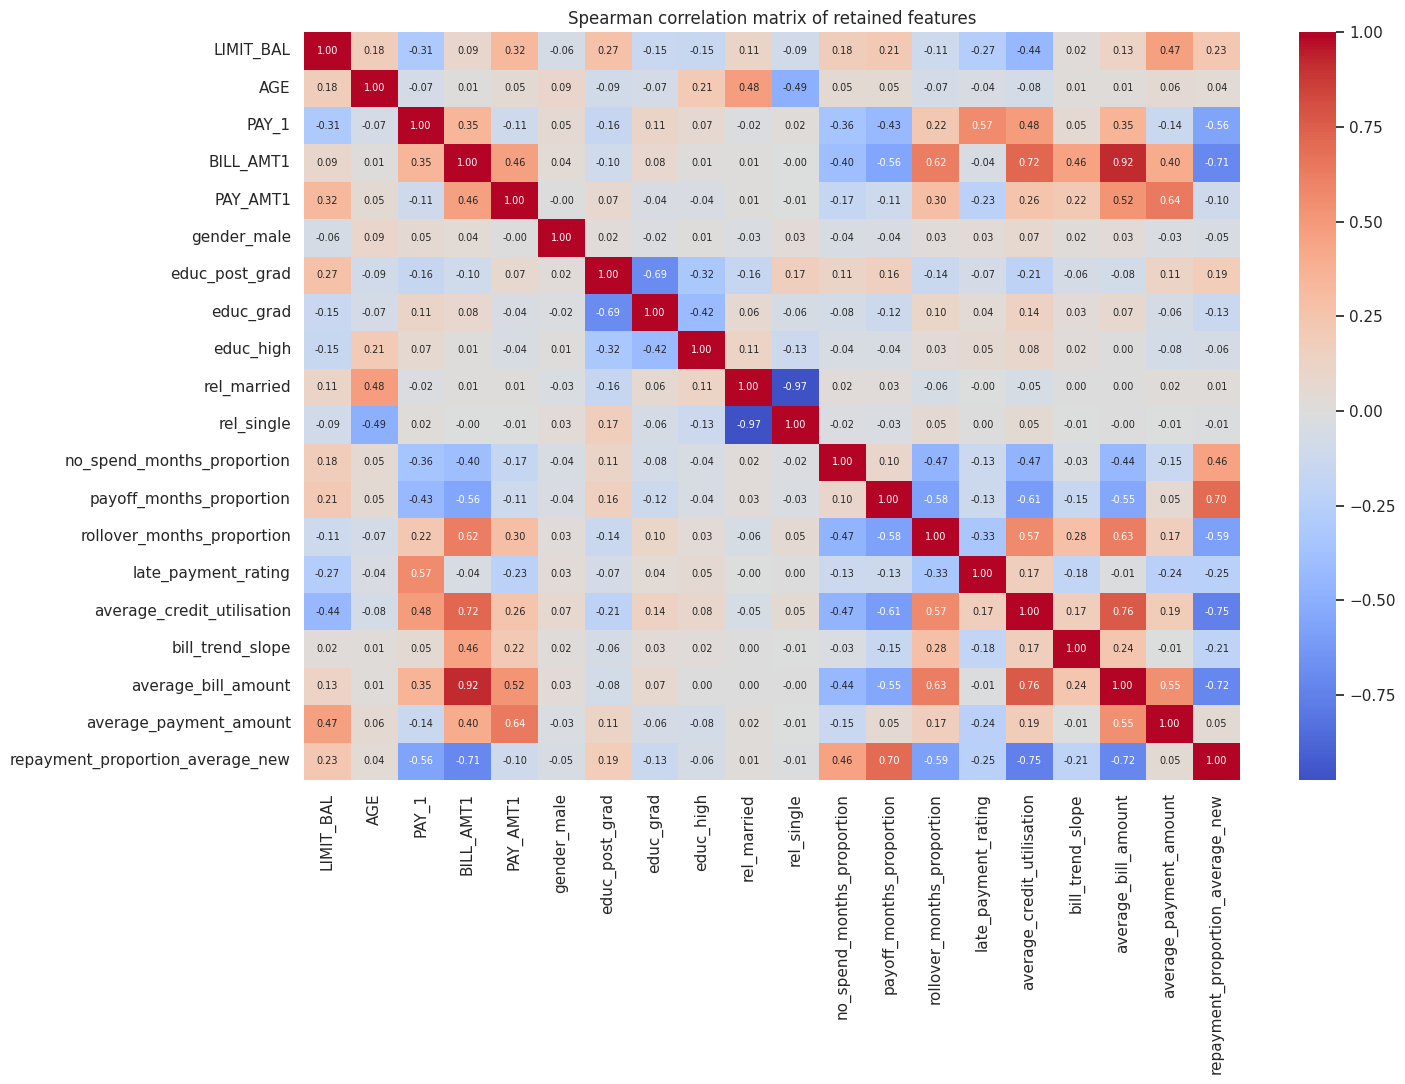

Missing values: 0
Infinite numeric values: 0


In [5]:
# Spearman correlation between the final predictor features (excluding target and selected raw features).
feature_columns = [c for c in df.columns if c != "default"]
corr = df[feature_columns].corr(method="spearman")

plt.figure(figsize=(15, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation matrix of retained features")
plt.tight_layout()
plt.show()

print("Missing values:", int(df.isna().sum().sum()))
print("Infinite numeric values:", int(np.isinf(df.select_dtypes(include=np.number)).sum().sum()))

## 6. Train, Validation and Test Sets

The data is split into three stratified subsets:

- **60% training:** used to fit models and perform cross-validation.
- **20% validation:** used to compare classification thresholds and make model-selection decisions.
- **20% test:** held back for the final evaluation.

Stratification preserves approximately the same proportion of defaulting and non-defaulting customers in each subset. The same split is used for all three models to make the comparison consistent.

In [6]:
X = df.drop(columns=["default"])
y = df["default"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp
)

print("Training:", X_train.shape, "Default rate:", round(y_train.mean(), 3))
print("Validation:", X_val.shape, "Default rate:", round(y_val.mean(), 3))
print("Test:", X_test.shape, "Default rate:", round(y_test.mean(), 3))

Training: (17156, 20) Default rate: 0.217
Validation: (5719, 20) Default rate: 0.217
Test: (5719, 20) Default rate: 0.217


## 7. Evaluation Approach

Accuracy measures overall correctness, but it can be misleading when one class is more common than the other. Precision measures how many predicted defaults were actual defaults; recall measures how many actual defaults were identified. F1-score balances precision and recall. ROC-AUC measures discrimination across probability thresholds.

A lower classification threshold generally increases recall but can reduce precision. Threshold selection is therefore performed using the validation set, not the test set. The test set is reserved for the final assessment.

In [7]:
def evaluate_predictions(model_name, y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

def show_evaluation(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    print(classification_report(y_true, predictions, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_true, predictions))

def choose_threshold(y_true, probabilities, thresholds=np.arange(0.20, 0.81, 0.05)):
    rows = []
    for threshold in thresholds:
        rows.append(evaluate_predictions("validation", y_true, probabilities, float(threshold)))
    results = pd.DataFrame(rows)
    display(results.round(4))
    best_row = results.loc[results["F1"].idxmax()]
    print(f"Best validation F1 threshold: {best_row['Threshold']:.2f}")
    return float(best_row["Threshold"])

## 8. Logistic Regression Baseline

Logistic Regression is used as the baseline model. A `StandardScaler` is included in a pipeline because logistic regression is sensitive to the scale of input features. The scaler is fitted on the training data only and then applied consistently to validation and test data.

The standard model is fitted without class weighting. A balanced version is also evaluated to investigate the effect of compensating for the minority default class.

In [8]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
logistic_model.fit(X_train, y_train)

logistic_val_prob = logistic_model.predict_proba(X_val)[:, 1]
logistic_threshold = choose_threshold(y_val, logistic_val_prob)

logistic_test_prob = logistic_model.predict_proba(X_test)[:, 1]
logistic_result = evaluate_predictions("Logistic Regression", y_test, logistic_test_prob, logistic_threshold)
print("Test-set evaluation at validation-selected threshold:")
show_evaluation(y_test, logistic_test_prob, logistic_threshold)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,validation,0.20,0.7349,0.4249,0.6298,0.5075,0.7633
1,validation,0.25,0.7480,0.4402,0.5968,0.5067,0.7633
2,validation,0.30,0.7741,0.4821,0.5637,0.5197,0.7633
3,validation,0.35,0.7994,0.5405,0.5008,0.5199,0.7633
4,validation,0.40,0.8129,0.5893,0.4524,0.5119,0.7633
5,validation,0.45,0.8202,0.6312,0.4113,0.4980,0.7633
6,validation,0.50,0.8182,0.6572,0.3371,0.4456,0.7633
7,validation,0.55,0.8133,0.6727,0.2702,0.3855,0.7633
8,validation,0.60,0.8075,0.6787,0.2129,0.3241,0.7633
9,validation,0.65,0.8042,0.7222,0.1573,0.2583,0.7633


Best validation F1 threshold: 0.35
Test-set evaluation at validation-selected threshold:
              precision    recall  f1-score   support

           0       0.88      0.89      0.88      4480
           1       0.58      0.54      0.56      1239

    accuracy                           0.81      5719
   macro avg       0.73      0.72      0.72      5719
weighted avg       0.81      0.81      0.81      5719

Confusion matrix:
 [[3985  495]
 [ 569  670]]


In [9]:
# Balanced Logistic Regression provides a second baseline configuration.
balanced_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"))
])
balanced_logistic.fit(X_train, y_train)
balanced_logistic_val_prob = balanced_logistic.predict_proba(X_val)[:, 1]
balanced_logistic_threshold = choose_threshold(y_val, balanced_logistic_val_prob)
balanced_logistic_test_prob = balanced_logistic.predict_proba(X_test)[:, 1]
balanced_logistic_result = evaluate_predictions(
    "Logistic Regression (balanced)", y_test, balanced_logistic_test_prob, balanced_logistic_threshold
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,validation,0.20,0.2938,0.2312,0.9710,0.3735,0.7648
1,validation,0.25,0.3681,0.2484,0.9452,0.3934,0.7648
2,validation,0.30,0.4749,0.2784,0.8927,0.4244,0.7648
3,validation,0.35,0.5980,0.3259,0.7992,0.4630,0.7648
4,validation,0.40,0.6924,0.3843,0.6952,0.4950,0.7648
5,validation,0.45,0.7260,0.4151,0.6444,0.5049,0.7648
6,validation,0.50,0.7396,0.4306,0.6234,0.5094,0.7648
7,validation,0.55,0.7517,0.4457,0.5960,0.5100,0.7648
8,validation,0.60,0.7690,0.4727,0.5661,0.5152,0.7648
9,validation,0.65,0.7935,0.5243,0.5137,0.5189,0.7648


Best validation F1 threshold: 0.65


## 9. Decision Tree

A Decision Tree predicts the target by recursively splitting the data according to feature values. The Gini criterion measures the impurity of a node; a split is preferred when it produces child nodes with lower weighted impurity.

Hyperparameter tuning was performed using `RandomizedSearchCV` with stratified five-fold cross-validation and F1-score as the optimisation metric. The search evaluated 50 candidates, resulting in 250 model fits. The best parameters recorded from that experiment were:

- `criterion='gini'`
- `max_depth=4`
- `min_samples_split=20`
- `min_samples_leaf=10`
- `class_weight='balanced'`

The next cell evaluates this selected configuration using five-fold cross-validation on the training set, then fits it on the full training set. The validation set is used to select a classification threshold; the test set remains held back for final evaluation.

In [10]:
best_tree_parameters = {
    "criterion": "gini",
    "max_depth": 4,
    "min_samples_split": 20,
    "min_samples_leaf": 10,
    "class_weight": "balanced"
}

decision_tree = DecisionTreeClassifier(**best_tree_parameters, random_state=RANDOM_STATE)
tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tree_cv_scores = cross_val_score(
    decision_tree, X_train, y_train, cv=tree_cv, scoring="f1", n_jobs=-1
)
print("Selected parameters:", best_tree_parameters)
print("Five-fold cross-validation F1 scores:", np.round(tree_cv_scores, 4))
print("Mean cross-validation F1:", round(tree_cv_scores.mean(), 4))

decision_tree.fit(X_train, y_train)

Selected parameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_split': 20, 'min_samples_leaf': 10, 'class_weight': 'balanced'}
Five-fold cross-validation F1 scores: [0.5239 0.5588 0.5363 0.5302 0.5378]
Mean cross-validation F1: 0.5374


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [11]:
tree_val_prob = decision_tree.predict_proba(X_val)[:, 1]
tree_threshold = choose_threshold(y_val, tree_val_prob)
tree_test_prob = decision_tree.predict_proba(X_test)[:, 1]
tree_result = evaluate_predictions("Decision Tree", y_test, tree_test_prob, tree_threshold)
print("Test-set evaluation at validation-selected threshold:")
show_evaluation(y_test, tree_test_prob, tree_threshold)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,validation,0.20,0.2168,0.2168,1.0000,0.3564,0.7679
1,validation,0.25,0.4786,0.2804,0.8968,0.4272,0.7679
2,validation,0.30,0.5275,0.2974,0.8653,0.4427,0.7679
3,validation,0.35,0.6102,0.3337,0.8000,0.4709,0.7679
4,validation,0.40,0.6449,0.3537,0.7710,0.4849,0.7679
5,validation,0.45,0.6832,0.3787,0.7202,0.4964,0.7679
6,validation,0.50,0.7778,0.4892,0.5653,0.5245,0.7679
7,validation,0.55,0.7842,0.5022,0.5581,0.5286,0.7679
8,validation,0.60,0.7977,0.5334,0.5347,0.5340,0.7679
9,validation,0.65,0.7980,0.5347,0.5282,0.5314,0.7679


Best validation F1 threshold: 0.60
Test-set evaluation at validation-selected threshold:
              precision    recall  f1-score   support

           0       0.88      0.87      0.88      4480
           1       0.55      0.56      0.56      1239

    accuracy                           0.81      5719
   macro avg       0.71      0.72      0.72      5719
weighted avg       0.81      0.81      0.81      5719

Confusion matrix:
 [[3908  572]
 [ 543  696]]


### 9.1 Decision Tree Visualisation

The tree can be visualised to inspect the first few levels of its decision structure. This provides an indication of how the model uses the selected features to separate customers into predicted classes.

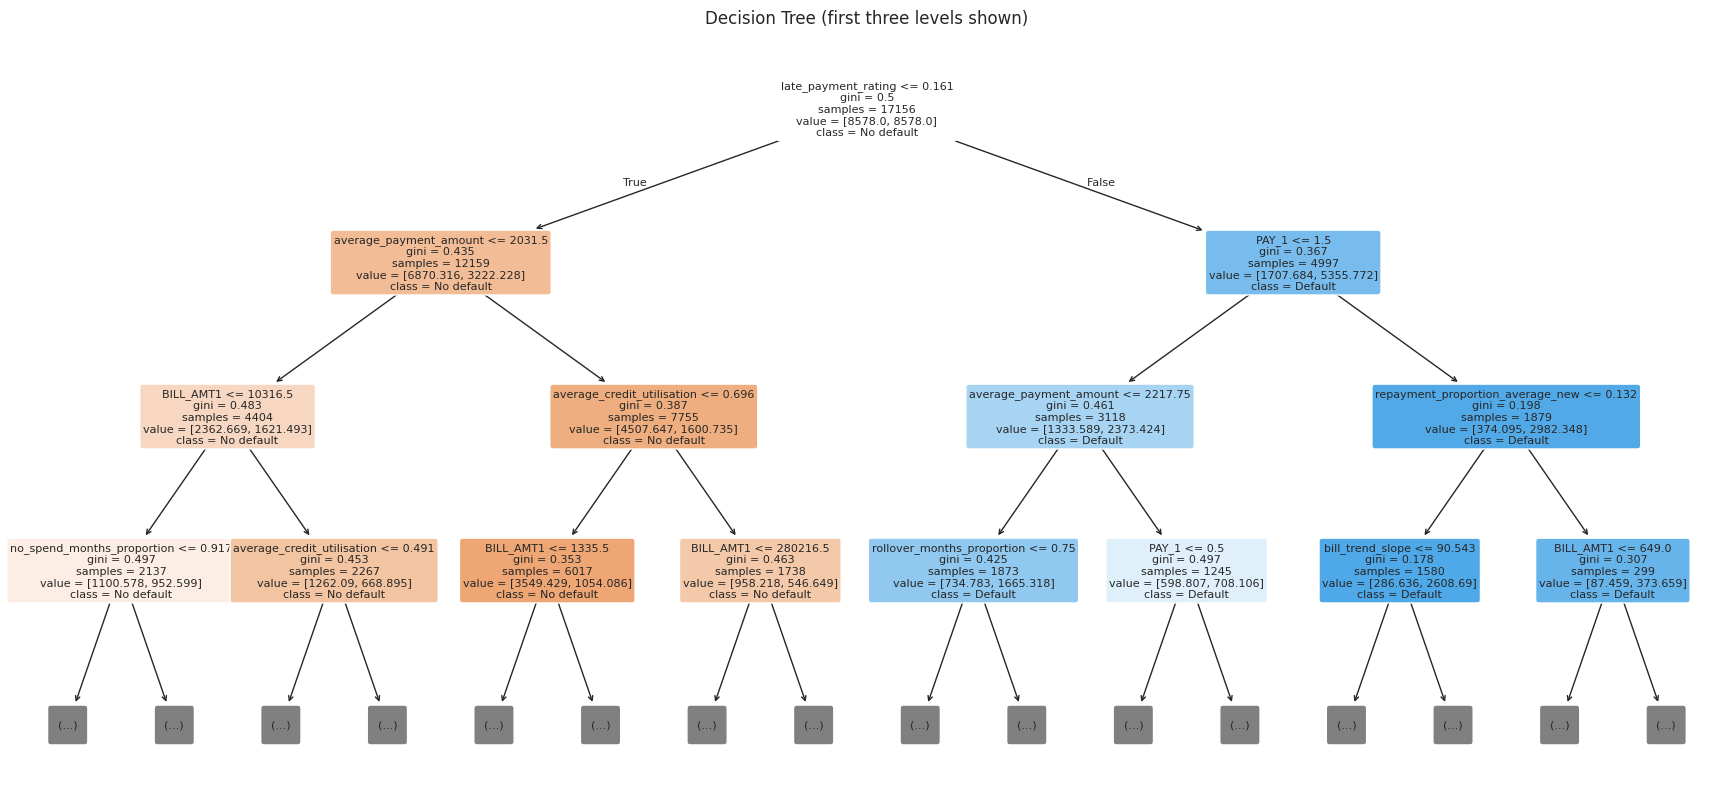

In [12]:
plt.figure(figsize=(22, 10))
plot_tree(
    decision_tree,
    feature_names=X_train.columns,
    class_names=["No default", "Default"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (first three levels shown)")
plt.show()

## 10. Random Forest

A Random Forest is an ensemble learning method that trains multiple decision trees using bootstrap samples of the training data and random subsets of features. The individual tree predictions are combined to produce the final prediction.

Compared with a single decision tree, this approach can reduce variance and improve generalisation. The trade-off is reduced interpretability because the final prediction is based on an ensemble rather than one set of decision rules.

The initial model uses 200 trees and balanced class weights. These settings provide a practical baseline for comparison; they are not claimed to be the result of an exhaustive Random Forest hyperparameter search.

In [13]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_forest.fit(X_train, y_train)

rf_val_prob = random_forest.predict_proba(X_val)[:, 1]
rf_threshold = choose_threshold(y_val, rf_val_prob)
rf_test_prob = random_forest.predict_proba(X_test)[:, 1]
rf_result = evaluate_predictions("Random Forest", y_test, rf_test_prob, rf_threshold)

print("Test-set evaluation at validation-selected threshold:")
show_evaluation(y_test, rf_test_prob, rf_threshold)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,validation,0.20,0.2924,0.2327,0.9855,0.3765,0.7799
1,validation,0.25,0.3976,0.2585,0.9516,0.4065,0.7799
2,validation,0.30,0.5205,0.2963,0.8806,0.4434,0.7799
3,validation,0.35,0.6059,0.3323,0.8105,0.4714,0.7799
4,validation,0.40,0.6832,0.3808,0.7371,0.5022,0.7799
5,validation,0.45,0.7346,0.4278,0.6637,0.5202,0.7799
6,validation,0.50,0.7603,0.4598,0.6048,0.5225,0.7799
7,validation,0.55,0.7802,0.4940,0.5637,0.5266,0.7799
8,validation,0.60,0.7940,0.5248,0.5298,0.5273,0.7799
9,validation,0.65,0.8092,0.5708,0.4847,0.5242,0.7799


Best validation F1 threshold: 0.60
Test-set evaluation at validation-selected threshold:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4480
           1       0.56      0.56      0.56      1239

    accuracy                           0.81      5719
   macro avg       0.72      0.72      0.72      5719
weighted avg       0.81      0.81      0.81      5719

Confusion matrix:
 [[3923  557]
 [ 541  698]]


### 10.1 Random Forest Feature Importance

Random Forest feature importance provides an indication of which input variables contributed most to reducing impurity across the ensemble. It is useful for interpretation, although it should not be treated as proof of causation.

,Importance
late_payment_rating,0.300176
PAY_1,0.238982
rollover_months_proportion,0.090437
average_payment_amount,0.058647
repayment_proportion_average_new,0.056912
LIMIT_BAL,0.055766
average_credit_utilisation,0.048625
PAY_AMT1,0.036803
average_bill_amount,0.027643
BILL_AMT1,0.026556


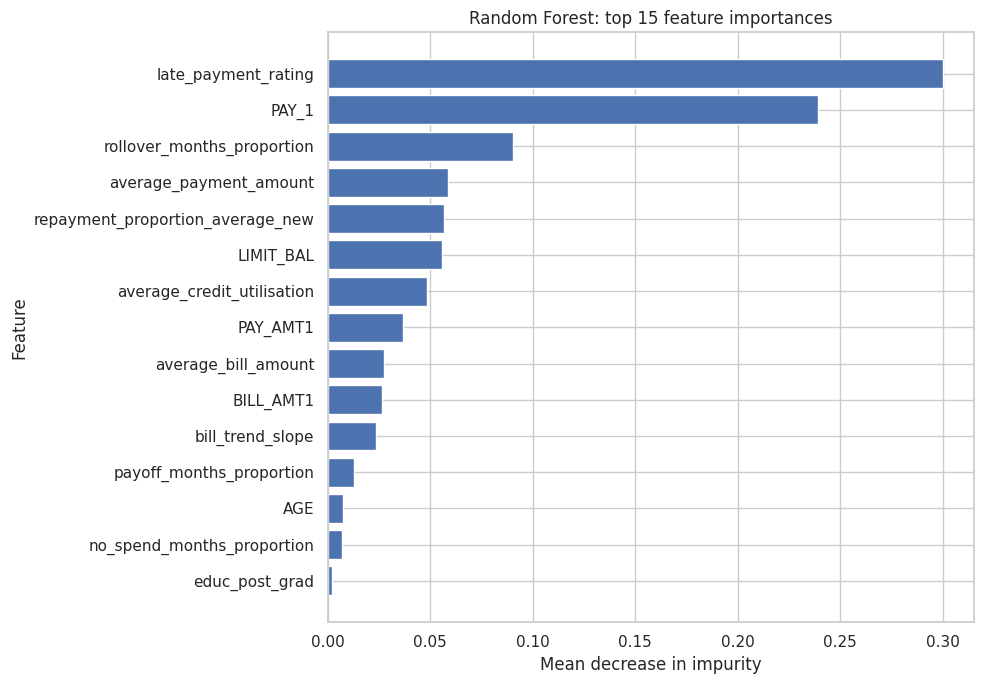

In [14]:
rf_importance = pd.Series(
    random_forest.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

display(rf_importance.to_frame("Importance").head(15))
plt.figure(figsize=(10, 7))
plt.barh(rf_importance.head(15).index[::-1], rf_importance.head(15).values[::-1])
plt.title("Random Forest: top 15 feature importances")
plt.xlabel("Mean decrease in impurity")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 11. Model Comparison

The following table compares the models on the same held-out test set. Each model's classification threshold was selected using the validation set. The test set was not used to select model parameters or thresholds.

The most appropriate model depends on the relative cost of false negatives (failing to identify a customer who defaults) and false positives (incorrectly flagging a customer who does not default). F1-score provides one balance between precision and recall, but business costs should ultimately guide the choice.

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Random Forest,0.60,0.8080,0.5562,0.5634,0.5597,0.7889
Logistic Regression,0.35,0.8140,0.5751,0.5408,0.5574,0.7837
Decision Tree,0.60,0.8050,0.5489,0.5617,0.5552,0.7732
Logistic Regression (balanced),0.65,0.8092,0.5611,0.5488,0.5549,0.7837


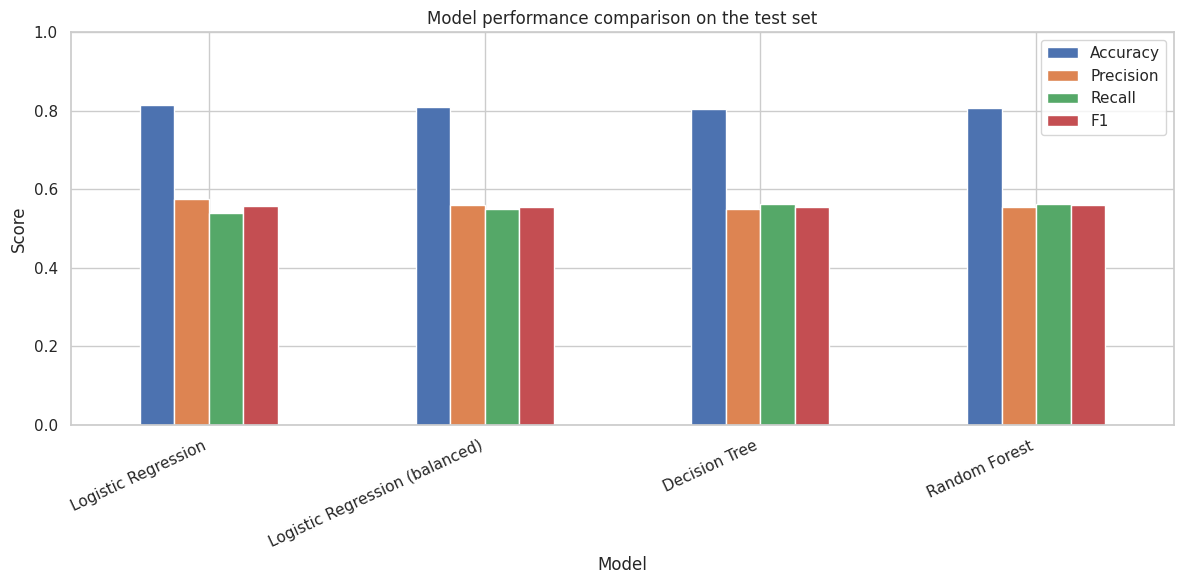

In [15]:
comparison = pd.DataFrame([
    logistic_result,
    balanced_logistic_result,
    tree_result,
    rf_result
]).set_index("Model")
display(comparison.round(4).sort_values("F1", ascending=False))

comparison[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
plt.title("Model performance comparison on the test set")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 12. Conclusion

This project applied feature engineering and classification techniques to the problem of credit card default prediction. The preprocessing stage transformed categorical variables and six months of repayment and billing history into a smaller set of demographic, behavioural and financial indicators.

Spearman correlation analysis was used to identify redundant engineered measures. The modelling stage compared Logistic Regression, a single Decision Tree and a Random Forest. Evaluation considered accuracy, precision, recall, F1-score and ROC-AUC, with particular attention to the default class.

The final model should be selected by considering the comparison table above and the intended balance between identifying actual defaulters and avoiding false alarms. A high accuracy score alone is not sufficient evidence of a good default prediction model when the target classes are imbalanced.

### Limitations and possible improvements

- The engineered features summarise historical behaviour and may not capture all relevant changes in a customer's circumstances.
- Feature importance indicates predictive contribution within a model, not causation.
- A more extensive Random Forest hyperparameter search could be performed if additional time were available.
- Threshold selection depends on the relative costs of false positives and false negatives; these costs were not specified in the dataset.
- Further work could investigate probability calibration and additional ensemble methods such as Gradient Boosting.

### Reproducibility

Run the notebook from top to bottom. The original CSV file must be available at `../data/credit_card_default_data.csv` relative to the notebook. The random state is fixed at 42 for the train/validation/test split and model initialisation.